# 02 · Data Cleaning & Validation
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**Purpose.** Turn the raw file into an analysis-ready dataset through a *reasoned* and *reproducible* process. For every issue I (1) detect it, (2) investigate why it exists, (3) decide whether to remove, impute, flag or retain, and (4) justify that decision.

**Guiding principle:** do not change data unless I can explain why. A cleaning step that silently invents or deletes information is a bug, not a fix.

**Contents**
1. Setup
2. Missing data: identify, investigate, decide
3. Data validation
   - 3.1 Impossible percentages and invalid ranges
   - 3.2 Composition checks (race and funding shares sum to 100)
   - 3.3 Duplicate institutions
   - 3.4 Inconsistent categories
   - 3.5 Values appropriate for the institution level
   - 3.6 Student-teacher ratio consistency
   - 3.7 Ceiling values
   - 3.8 Outliers
4. Scope decision: K-12 versus colleges and universities
5. Cleaning decision log
6. Apply the reproducible pipeline and save the cleaned data
7. Before / after summary

## 1. Setup

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from utils import PATHS, set_style, save_fig
from data_cleaning import clean, make_k12, K12_LEVELS, HIGHER_ED, PCT_COLS, RACE_COLS, FUNDING_COLS, NO_GRADUATION_LEVELS
set_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

raw = pd.read_csv(PATHS['raw'])
print(f'Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns')

Raw data: 5,000 rows x 35 columns


## 2. Missing data: identify, investigate, decide

### 2.1 Identify

In [2]:
miss_cols = ['avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct']
summary = pd.DataFrame({
    'n_missing': raw[miss_cols].isna().sum(),
    'pct_missing': (raw[miss_cols].isna().mean() * 100).round(1),
    'n_available': raw[miss_cols].notna().sum(),
})
summary

,n_missing,pct_missing,n_available
avg_sat_score,3375,67.5,1625
avg_act_score,3375,67.5,1625
ap_ib_participation_pct,3579,71.6,1421
postsecondary_enrollment_pct,3579,71.6,1421


### 2.2 Investigate *why* the values are missing

The standard question is: is the missingness **random** or does it have a **cause**? If it has a cause, the right treatment depends on that cause. I test whether *level* fully explains it.

In [3]:
rows = []
for col in miss_cols:
    available_levels = raw.groupby('level')[col].apply(lambda s: s.notna().any())
    levels_with_data = available_levels[available_levels].index.tolist()
    levels_without   = available_levels[~available_levels].index.tolist()
    # Within the levels where the metric exists, how many values are STILL missing?
    still_missing = raw.loc[raw['level'].isin(levels_with_data), col].isna().sum()
    rows.append({
        'column': col,
        'levels_with_data': ', '.join(levels_with_data),
        'levels_always_missing': ', '.join(levels_without),
        'missing_inside_levels_that_report_it': still_missing,
    })
pd.DataFrame(rows)

,column,levels_with_data,levels_always_missing,missing_inside_levels_that_report_it
0,avg_sat_score,"4-Year University, High School, K-12 Combined","2-Year College, Elementary School, Middle School",0
1,avg_act_score,"4-Year University, High School, K-12 Combined","2-Year College, Elementary School, Middle School",0
2,ap_ib_participation_pct,"High School, K-12 Combined","2-Year College, 4-Year University, Elementary ...",0
3,postsecondary_enrollment_pct,"High School, K-12 Combined","2-Year College, 4-Year University, Elementary ...",0


**Finding.** Inside the levels that report a metric, **zero** values are missing. Outside them, **every** value is missing. So the missingness is a deterministic function of school level: it is *structural* (the metric is not applicable), not accidental. In statistical language this is not MCAR (missing completely at random); it is missing *by design*.

### 2.3 Why imputing or zero-filling would be wrong

In [4]:
sat = raw['avg_sat_score']
print(f"Real mean SAT (schools that report it)        : {sat.mean():.0f}")
print(f"Mean SAT if missing values were filled with 0 : {sat.fillna(0).mean():.0f}")
print(f"Mean SAT if missing were filled with the mean : {sat.fillna(sat.mean()).mean():.0f}  (looks fine, but...)")
print()
print(f"...that would assign an SAT score to {sat.isna().sum():,} institutions "
      f"({sat.isna().mean():.0%}) that do not administer the SAT at all.")

Real mean SAT (schools that report it)        : 1233
Mean SAT if missing values were filled with 0 : 401
Mean SAT if missing were filled with the mean : 1233  (looks fine, but...)

...that would assign an SAT score to 3,375 institutions (68%) that do not administer the SAT at all.


### 2.4 Decision

| Column(s) | Cause | Decision | Justification |
|---|---|---|---|
| `avg_sat_score`, `avg_act_score` | Not applicable for elementary, middle, 2-year colleges | **Retain as NaN** (do not impute, do not drop rows) | Imputing would fabricate scores for institutions with no such test. Any analysis of these columns is restricted to levels that report them. |
| `ap_ib_participation_pct`, `postsecondary_enrollment_pct` | Not applicable for elementary, middle, 2-year, 4-year | **Retain as NaN** | Same reasoning. Only about 1,400 high-school and K-12 combined rows can support postsecondary analysis. |

**Why not drop rows with missing values?** That would delete about 72% of the data, including *all* elementary and middle schools, to preserve four columns that my primary question does not even use. My primary target (`math_proficiency_pct`) and predictors have **no** missing values, so these four columns are simply left out of the primary models.

## 3. Data validation

### 3.1 Impossible percentages and invalid ranges
Every column that is a percentage must lie between 0 and 100.

In [5]:
range_check = pd.DataFrame({
    'min': raw[PCT_COLS].min(),
    'max': raw[PCT_COLS].max(),
    'n_below_0': (raw[PCT_COLS] < 0).sum(),
    'n_above_100': (raw[PCT_COLS] > 100).sum(),
}).round(2)
display(range_check)
print('Total impossible percentage values:', int(range_check[['n_below_0', 'n_above_100']].sum().sum()))

,min,max,n_below_0,n_above_100
percent_free_reduced_lunch,0.0,98.0,0,0
racial_white_pct,3.9,92.1,0,0
racial_black_pct,0.8,67.3,0,0
racial_hispanic_pct,1.5,83.2,0,0
racial_asian_pct,0.3,36.0,0,0
racial_native_pct,0.1,9.6,0,0
racial_two_or_more_pct,0.5,25.4,0,0
special_education_pct,4.0,25.0,0,0
english_learner_pct,0.0,33.2,0,0
federal_funding_pct,0.0,32.8,0,0


Total impossible percentage values: 0


In [6]:
# Non-percentage columns: check plausible ranges.
other = pd.DataFrame({
    'min': raw[['total_enrollment', 'number_of_teachers', 'student_teacher_ratio', 'per_pupil_expenditure_usd', 'avg_sat_score', 'avg_act_score']].min(),
    'max': raw[['total_enrollment', 'number_of_teachers', 'student_teacher_ratio', 'per_pupil_expenditure_usd', 'avg_sat_score', 'avg_act_score']].max(),
})
display(other)
print('Non-positive enrollment or teachers:', int(((raw.total_enrollment <= 0) | (raw.number_of_teachers <= 0)).sum()))
print('SAT outside 400-1600:', int(((raw.avg_sat_score < 400) | (raw.avg_sat_score > 1600)).sum()))
print('ACT outside 1-36    :', int(((raw.avg_act_score < 1) | (raw.avg_act_score > 36)).sum()))

,min,max
total_enrollment,80.0,45252.0
number_of_teachers,5.0,3279.0
student_teacher_ratio,6.0,30.0
per_pupil_expenditure_usd,7500.0,50601.0
avg_sat_score,909.0,1528.0
avg_act_score,17.1,33.9


Non-positive enrollment or teachers: 0
SAT outside 400-1600: 0
ACT outside 1-36    : 0


**Finding.** No impossible percentages, no negative or zero counts, and SAT/ACT values sit inside their valid scales. No rows need to be removed for range violations.

### 3.2 Composition checks
Race percentages should sum to 100 for each institution, and so should the three funding-source percentages.

In [7]:
race_sum = raw[RACE_COLS].sum(axis=1)
fund_sum = raw[FUNDING_COLS].sum(axis=1)

check = pd.DataFrame({'race_sum': race_sum.describe(), 'funding_sum': fund_sum.describe()}).round(2)
display(check)
print('Rows where race shares differ from 100 by more than 0.5   :', int(((race_sum - 100).abs() > 0.5).sum()))
print('Rows where funding shares differ from 100 by more than 0.5:', int(((fund_sum - 100).abs() > 0.5).sum()))

,race_sum,funding_sum
count,5000.0,5000.0
mean,100.0,100.0
std,0.0,0.0
min,100.0,100.0
25%,100.0,100.0
50%,100.0,100.0
75%,100.0,100.0
max,100.0,100.0


Rows where race shares differ from 100 by more than 0.5   : 0
Rows where funding shares differ from 100 by more than 0.5: 0


**Finding.** Both sets of shares sum to 100 in every row, so the composition columns are internally consistent. One consequence matters later: the three funding shares are perfectly dependent (any one equals 100 minus the other two), so I should not enter all three into a regression model. I will drop one.

### 3.3 Duplicate institutions
I test three levels of "duplicate": same ID, identical rows ignoring the ID, and the same name in the same place.

In [8]:
print('Duplicate institution_id values        :', raw['institution_id'].duplicated().sum())
print('Fully duplicated rows                  :', raw.duplicated().sum())
print('Duplicated rows ignoring institution_id:', raw.drop(columns='institution_id').duplicated().sum())

place_key = ['institution_name', 'state_code', 'county']
same_place = raw.groupby(place_key).size()
print(f"\nName + state + county combinations that appear more than once: {(same_place > 1).sum()}")

Duplicate institution_id values        : 0
Fully duplicated rows                  : 0
Duplicated rows ignoring institution_id: 0

Name + state + county combinations that appear more than once: 112


In [9]:
# Are those same-name pairs really the same institution? A true duplicate would also share
# level, enrollment and teacher counts.
strict_key = place_key + ['level', 'total_enrollment', 'number_of_teachers']
true_dupes = raw.duplicated(subset=strict_key, keep=False)
print('Rows sharing name, place, level, enrollment AND teacher count:', int(true_dupes.sum()))

# Show a couple of same-name, same-place examples to see how they differ.
examples = same_place[same_place > 1].index[:3]
for key in examples:
    mask = (raw[place_key] == pd.Series(key, index=place_key)).all(axis=1)
    display(raw.loc[mask, ['institution_id', 'institution_name', 'county', 'level', 'total_enrollment', 'number_of_teachers', 'math_proficiency_pct']])

Rows sharing name, place, level, enrollment AND teacher count: 0


,institution_id,institution_name,county,level,total_enrollment,number_of_teachers,math_proficiency_pct
1269,US-EDU-11270,Carver Comprehensive High School,Collin County,High School,1433,68,73.8
3435,US-EDU-13436,Carver Comprehensive High School,Collin County,High School,675,52,73.0


,institution_id,institution_name,county,level,total_enrollment,number_of_teachers,math_proficiency_pct
283,US-EDU-10284,Carver Primary School,Richmond County,Elementary School,264,26,71.7
3747,US-EDU-13748,Carver Primary School,Richmond County,Elementary School,608,57,77.6


,institution_id,institution_name,county,level,total_enrollment,number_of_teachers,math_proficiency_pct
2282,US-EDU-12283,Cedar Creek Academy,Madison County,High School,1946,109,50.0
3995,US-EDU-13996,Cedar Creek Academy,Madison County,High School,995,60,67.3


**Finding.** Every `institution_id` is unique and no row is duplicated. Some names repeat within the same county, but those rows differ in level, enrollment and outcomes, which is what you would expect for different schools with generic names (e.g. several "Lincoln Elementary"-style names). **Decision: retain all rows; no deduplication.** `institution_id` is the reliable key.

### 3.4 Inconsistent categories
Checking for stray whitespace, inconsistent capitalisation, and mapping problems.

In [10]:
cat_cols = ['state_code', 'state_name', 'county', 'nces_locale', 'level', 'control', 'title_i_status', 'stem_certified_flag']

rows = []
for c in cat_cols:
    s = raw[c].astype(str)
    rows.append({
        'column': c,
        'n_unique': s.nunique(),
        'has_whitespace_issue': int((s != s.str.strip()).sum()),
        'case_variants': s.nunique() - s.str.strip().str.lower().nunique(),
    })
display(pd.DataFrame(rows))

print('States with more than one state_name:', int((raw.groupby('state_code')['state_name'].nunique() > 1).sum()))
print('State names with more than one code :', int((raw.groupby('state_name')['state_code'].nunique() > 1).sum()))

,column,n_unique,has_whitespace_issue,case_variants
0,state_code,51,0,0
1,state_name,51,0,0
2,county,104,0,0
3,nces_locale,8,0,0
4,level,6,0,0
5,control,5,0,0
6,title_i_status,4,0,0
7,stem_certified_flag,2,0,0


States with more than one state_name: 0
State names with more than one code : 0


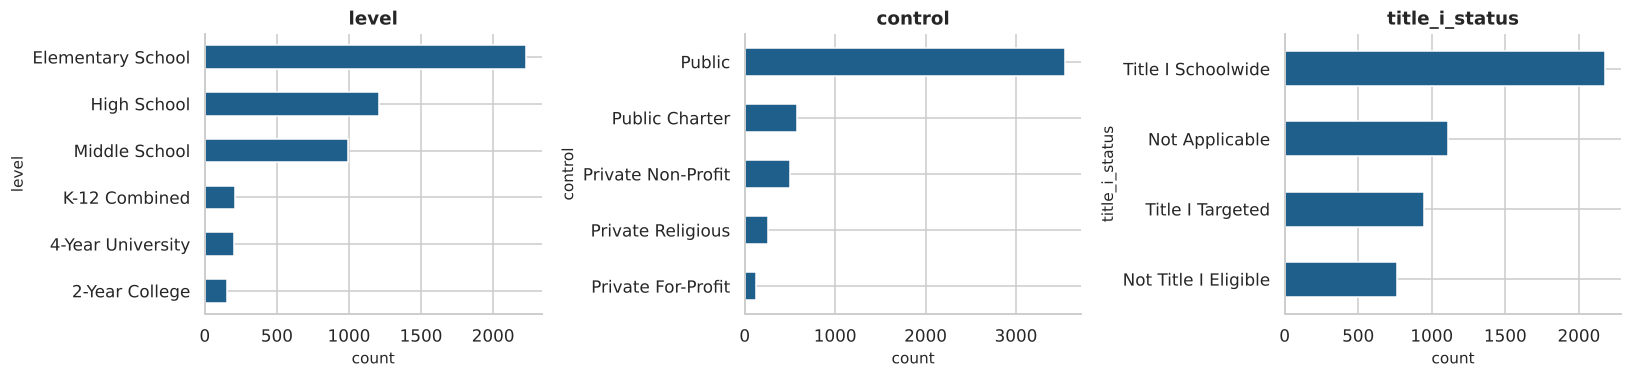

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, c in zip(ax, ['level', 'control', 'title_i_status']):
    raw[c].value_counts().sort_values().plot.barh(ax=a, color='#1f5f8b')
    a.set_title(c); a.set_xlabel('count')
plt.tight_layout(); save_fig('02_category_counts'); plt.show()

**Finding.** No whitespace problems, no capitalisation variants, and state codes map one-to-one to state names. Categories are consistent. I still strip whitespace inside the pipeline as a safeguard so the cleaning step stays robust if the file is refreshed.

### 3.5 Are values appropriate for the institution level?
Some variables only make sense for certain kinds of institution. I cross-check the categorical structure first:

In [12]:
display(pd.crosstab(raw['level'], raw['title_i_status']))
display(pd.crosstab(raw['control'], raw['title_i_status']))

title_i_status,Not Applicable,Not Title I Eligible,Title I Schoolwide,Title I Targeted
level,,,,
2-Year College,154,0,0,0
4-Year University,204,0,0,0
Elementary School,341,377,1034,473
High School,211,185,584,229
K-12 Combined,39,33,102,38
Middle School,159,172,460,205


title_i_status,Not Applicable,Not Title I Eligible,Title I Schoolwide,Title I Targeted
control,,,,
Private For-Profit,121,0,0,0
Private Non-Profit,499,0,0,0
Private Religious,256,0,0,0
Public,232,654,1858,803
Public Charter,0,113,322,142


**Finding (Title I).** Colleges and universities are *always* "Not Applicable" for Title I, which is logical because Title I is a K-12 programme. Among K-12 schools, "Not Applicable" appears for **every private school and for no public or charter school**, which matches reality (private schools do not receive Title I funds). So "Not Applicable" is a meaningful category (it marks private schools), and I keep it rather than treating it as missing. A consequence for later: in the K-12 data, Title I status partly overlaps with school *control* (public versus private).

Now the graduation rate, which had no missing values in the raw file:

In [13]:
grad = raw.groupby('level')['graduation_rate_pct'].agg(['count', 'min', 'mean', 'max']).round(1)
grad

,count,min,mean,max
level,,,,
2-Year College,154,77.2,89.6,99.5
4-Year University,204,74.5,88.3,99.5
Elementary School,2225,62.0,84.7,99.5
High School,1209,63.9,84.4,99.5
K-12 Combined,212,60.0,84.4,99.5
Middle School,996,63.2,84.9,99.5


**Finding (graduation rate).** Elementary and middle schools each have a graduation rate for *every* row, with averages close to those of high schools. Elementary and middle schools do not graduate students (in the usual sense), so these numbers cannot be a real graduation outcome for those institutions. Keeping them would let a meaningless variable leak into any analysis.

**Decision:** set `graduation_rate_pct` to **NaN** for Elementary and Middle schools, and keep it for High School, K-12 Combined, and the colleges, where a completion rate is meaningful. This is the opposite of the SAT/ACT situation: there the data were already missing for a good reason; here the data are *present* for a bad reason.

### 3.6 Student-teacher ratio consistency
`student_teacher_ratio` should be about `total_enrollment / number_of_teachers`.

In [14]:
calc = raw['total_enrollment'] / raw['number_of_teachers']
gap = (calc - raw['student_teacher_ratio']).abs()
print(gap.describe().round(3))

mismatch = gap > 0.5
print(f"\nRows with a gap larger than 0.5 students per teacher: {mismatch.sum()} ({mismatch.mean():.1%})")
print(f"Largest gap: {gap.max():.2f} students per teacher")
display(raw.loc[mismatch, ['level', 'total_enrollment', 'number_of_teachers', 'student_teacher_ratio']]
          .assign(calculated=calc[mismatch].round(1)).head(8))
print(raw.loc[mismatch, 'total_enrollment'].describe().round(0))

count    5000.000
mean        0.105
std         0.121
min         0.000
25%         0.028
50%         0.070
75%         0.139
max         1.500
dtype: float64

Rows with a gap larger than 0.5 students per teacher: 70 (1.4%)
Largest gap: 1.50 students per teacher


,level,total_enrollment,number_of_teachers,student_teacher_ratio,calculated
160,Elementary School,127,8,16.9,15.9
191,Middle School,317,16,19.3,19.8
202,Elementary School,402,19,21.7,21.2
216,Elementary School,120,7,16.1,17.1
223,High School,269,14,19.9,19.2
235,Elementary School,398,19,21.5,20.9
262,K-12 Combined,112,6,18.1,18.7
306,K-12 Combined,80,6,12.5,13.3


count     70.0
mean     211.0
std      106.0
min       80.0
25%      120.0
50%      198.0
75%      294.0
max      515.0
Name: total_enrollment, dtype: float64


**Finding.** The ratio matches enrollment divided by teachers almost exactly in 98.6% of rows. The 70 mismatches are small (the largest is about 1.5 students per teacher) and occur mostly in small schools, where a rounded teacher count changes the ratio noticeably. This looks like rounding, not corruption.

**Decision:** keep the original `student_teacher_ratio`, add a `str_calculated` column and a `str_mismatch_flag`, and test in the modelling notebooks that results do not depend on those 70 rows.

### 3.7 Ceiling values
A distribution that piles up at one exact value can mean a reporting cap, but it can also mean a structural pattern. I check which.

In [15]:
ceilings = pd.DataFrame({
    'max_value': [raw.reading_proficiency_pct.max(), raw.math_proficiency_pct.max(), raw.broadband_access_pct.max(), raw.graduation_rate_pct.max(), raw.local_funding_pct.max()],
    'n_at_max': [(raw.reading_proficiency_pct == raw.reading_proficiency_pct.max()).sum(),
                 (raw.math_proficiency_pct == raw.math_proficiency_pct.max()).sum(),
                 (raw.broadband_access_pct == raw.broadband_access_pct.max()).sum(),
                 (raw.graduation_rate_pct == raw.graduation_rate_pct.max()).sum(),
                 (raw.local_funding_pct == raw.local_funding_pct.max()).sum()],
}, index=['reading_proficiency_pct', 'math_proficiency_pct', 'broadband_access_pct', 'graduation_rate_pct', 'local_funding_pct'])
ceilings['pct_of_rows'] = (ceilings['n_at_max'] / len(raw) * 100).round(1)
display(ceilings)

,max_value,n_at_max,pct_of_rows
reading_proficiency_pct,98.0,121,2.4
math_proficiency_pct,96.0,84,1.7
broadband_access_pct,99.0,223,4.5
graduation_rate_pct,99.5,49,1.0
local_funding_pct,98.0,755,15.1


Two columns pile up noticeably: **proficiency scores** (reading at 98, math at 96) and **local funding** (98). These could be the same phenomenon (a reporting cap) or two different things. I investigate each separately, starting with local funding.

**Local funding at 98%: is it a cap?** If it were a cap, the rows should be scattered across school types. I check which institutions they are and what their full funding mix looks like.

In [16]:
at98 = raw[raw['local_funding_pct'] == 98]
print(f'Institutions with local funding = 98%: {len(at98)}')
print('\nTheir complete funding mix (distinct combinations):')
display(at98[['federal_funding_pct', 'state_funding_pct', 'local_funding_pct']].drop_duplicates())

ct = pd.crosstab(raw['control'], raw['local_funding_pct'] == 98, margins=True)
ct.columns = ['local funding is NOT 98%', 'local funding = 98%', 'All']
display(ct)

print('\nFunding-mix variation inside the other school types (local funding %):')
display(raw[raw['local_funding_pct'] != 98].groupby('control')['local_funding_pct'].agg(['count', 'mean', 'std']).round(1))

Institutions with local funding = 98%: 755

Their complete funding mix (distinct combinations):


,federal_funding_pct,state_funding_pct,local_funding_pct
1,0.0,2.0,98.0


,local funding is NOT 98%,local funding = 98%,All
control,,,
Private For-Profit,121,0,121
Private Non-Profit,0,499,499
Private Religious,0,256,256
Public,3547,0,3547
Public Charter,577,0,577
All,4245,755,5000



Funding-mix variation inside the other school types (local funding %):


,count,mean,std
control,,,
Private For-Profit,121,39.9,11.7
Public,3547,40.4,10.4
Public Charter,577,40.5,10.0


**Finding (local funding).** The 98% is **not a cap**. It is a *fixed funding mix* shared by **every** Private Non-Profit and Private Religious institution (755 in total): exactly 0% federal, 2% state and 98% local, with no variation at all. No public, charter or for-profit institution has it, and those groups show ordinary variation in their funding mix. So the pattern is **structural and tied to school control** (public versus private), not censoring.

**Why it matters.** For these 755 institutions the funding-share variables contain no information beyond "this is a private non-profit or religious school". In a model, `federal_funding_pct` and `local_funding_pct` therefore act partly as **stand-ins for public versus private control**, so I must not read them as independent funding effects.

**Decision:** retain all rows; add `private_fixed_funding_flag` (federal = 0, state = 2, local = 98); the funding shares were never used in the statistical models, and the ML model uses them only as context, with the caveat noted in notebook 05.

**Proficiency ceilings (reading 98, math 96).** These *do* look like genuine ceilings: they occur across many school types, and a proficiency percentage cannot meaningfully exceed its maximum. A value at a ceiling is *censored* (the true value may be higher) and slightly understates the spread at the top. **Decision:** retain; add `reading_capped_flag` and `math_capped_flag`, and test the effect in the sensitivity checks in notebook 04.

### 3.8 Outliers
I use Tukey's fences (1.5 × IQR) to *flag* unusual values, then decide on a case-by-case basis, because an outlier is not automatically an error.

In [17]:
out_cols = ['total_enrollment', 'per_pupil_expenditure_usd', 'student_teacher_ratio', 'broadband_access_pct',
            'math_proficiency_pct', 'reading_proficiency_pct', 'chronic_absenteeism_pct', 'percent_free_reduced_lunch']

rows = []
for c in out_cols:
    q1, q3 = raw[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((raw[c] < lo) | (raw[c] > hi)).sum()
    rows.append({'variable': c, 'lower_fence': round(lo, 1), 'upper_fence': round(hi, 1),
                 'n_outliers': n_out, 'pct_outliers': round(n_out / len(raw) * 100, 1),
                 'skewness': round(raw[c].skew(), 2)})
outlier_table = pd.DataFrame(rows).set_index('variable')
outlier_table

,lower_fence,upper_fence,n_outliers,pct_outliers,skewness
variable,,,,,
total_enrollment,-276.0,1628.0,480,9.6,6.42
per_pupil_expenditure_usd,7334.8,26364.8,152,3.0,0.96
student_teacher_ratio,5.8,23.9,28,0.6,0.16
broadband_access_pct,77.4,104.2,4,0.1,-0.13
math_proficiency_pct,12.8,107.2,7,0.1,-0.03
reading_proficiency_pct,19.1,110.8,10,0.2,-0.07
chronic_absenteeism_pct,4.0,36.0,21,0.4,-0.02
percent_free_reduced_lunch,-35.0,116.2,0,0.0,0.01


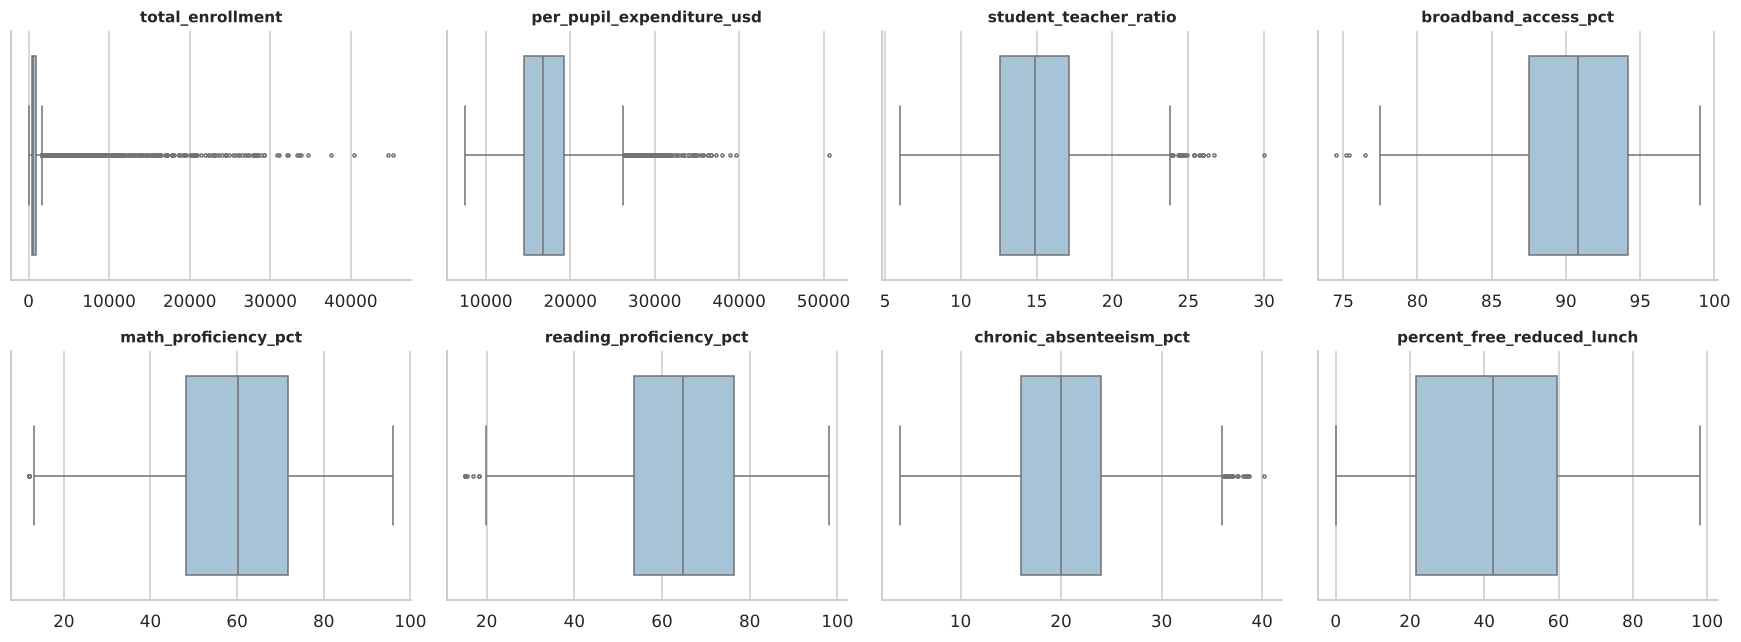

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for a, c in zip(axes.ravel(), out_cols):
    sns.boxplot(x=raw[c], ax=a, color='#9ec5e0', fliersize=2)
    a.set_title(c, fontsize=10); a.set_xlabel('')
plt.tight_layout(); save_fig('02_outlier_boxplots'); plt.show()

In [19]:
# Are the extreme-enrollment and extreme-spending rows plausible institutions, or errors?
display(raw.loc[raw.total_enrollment > raw.total_enrollment.quantile(.99), ['level', 'control', 'total_enrollment', 'number_of_teachers']]
          .groupby('level').agg(n=('level', 'size'), median_enrollment=('total_enrollment', 'median')))
display(raw.loc[raw.per_pupil_expenditure_usd > 35000, ['level', 'control', 'per_pupil_expenditure_usd', 'percent_free_reduced_lunch', 'math_proficiency_pct']]
          .groupby('level').agg(n=('level', 'size'), median_spend=('per_pupil_expenditure_usd', 'median'), median_math=('math_proficiency_pct', 'median')))

,n,median_enrollment
level,,
4-Year University,50,26675.5


,n,median_spend,median_math
level,,,
2-Year College,7,36374.0,96.00
4-Year University,2,37685.0,84.60
Elementary School,4,36705.5,82.25
Middle School,1,35449.0,75.20


**Finding.**
- **Enrollment** is strongly right-skewed across the full file, but that is driven by the **4-year universities**: the entire top 1% of enrollment values belong to them, with tens of thousands of students each, which is legitimate. Among K-12 schools enrollment is far more contained (maximum about 2,300) and only moderately skewed.
- **Per-pupil expenditure** has a long upper tail in the full file (152 flagged rows, of which 85 are colleges and universities). The K-12 tail is milder (maximum about $37k). Very high values look like real well-funded institutions, not typing mistakes.
- The proficiency, broadband and poverty variables have few or no outliers and are close to symmetric.

**Decision: retain all outliers.** Deleting real but unusual institutions would bias the picture towards "typical" schools. Instead I handle them analytically: (1) use `log(total_enrollment)` to tame the skew, (2) use heteroskedasticity-robust standard errors in regression, (3) add a `ppe_outlier_flag`, and (4) re-run the key model without flagged rows as a **sensitivity check** in notebook 04.

## 4. Scope decision: K-12 versus colleges and universities

My research question concerns **K-12 schools**. Before settling the scope I check how different colleges and universities really are on the variables that matter.

,n,mean_free_reduced_lunch,mean_math,mean_spend,mean_absenteeism,mean_enrollment
group,,,,,,
College / university,358,3.7,77.5,20994.8,16.7,10499.6
K-12 school,4642,44.2,58.7,16814.1,20.2,672.2


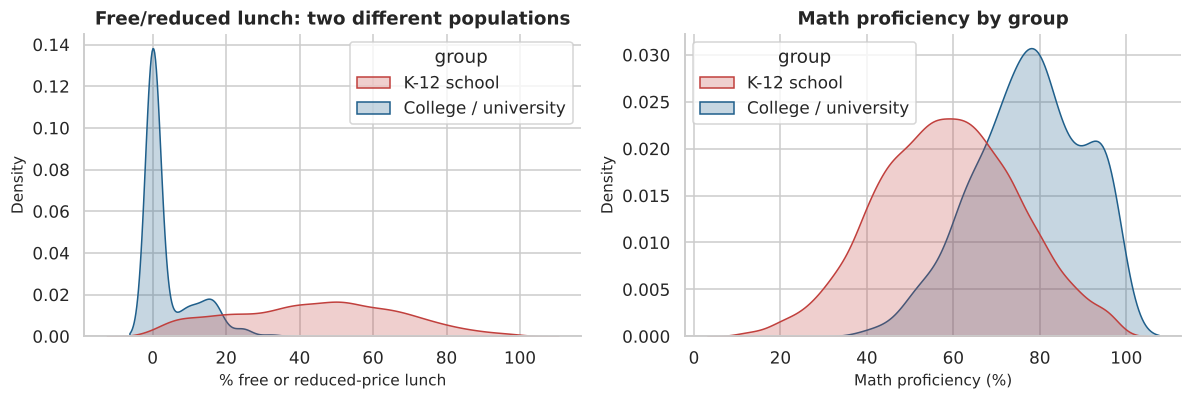

In [20]:
raw['group'] = np.where(raw['level'].isin(HIGHER_ED), 'College / university', 'K-12 school')
compare = raw.groupby('group').agg(
    n=('institution_id', 'size'),
    mean_free_reduced_lunch=('percent_free_reduced_lunch', 'mean'),
    mean_math=('math_proficiency_pct', 'mean'),
    mean_spend=('per_pupil_expenditure_usd', 'mean'),
    mean_absenteeism=('chronic_absenteeism_pct', 'mean'),
    mean_enrollment=('total_enrollment', 'mean'),
).round(1)
display(compare)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.kdeplot(data=raw, x='percent_free_reduced_lunch', hue='group', fill=True, common_norm=False, ax=ax[0], palette=['#c1403d', '#1f5f8b'])
ax[0].set_title('Free/reduced lunch: two different populations'); ax[0].set_xlabel('% free or reduced-price lunch')
sns.kdeplot(data=raw, x='math_proficiency_pct', hue='group', fill=True, common_norm=False, ax=ax[1], palette=['#c1403d', '#1f5f8b'])
ax[1].set_title('Math proficiency by group'); ax[1].set_xlabel('Math proficiency (%)')
plt.tight_layout(); save_fig('02_scope_k12_vs_higher_ed'); plt.show()
raw.drop(columns='group', inplace=True)

**Finding.** Colleges and universities have almost no free/reduced-lunch students (that measure applies to K-12), a much higher mean math score, and no Title I status. They are a different population measured by a different yardstick. Pooling them with K-12 schools would let institution *type* masquerade as a poverty effect and inflate the apparent link between poverty and outcomes.

**Decision:** keep all 5,000 cleaned rows in `institutions_clean.csv` for completeness, but run the analysis on the **K-12 subset** (Elementary, Middle, High, and K-12 Combined schools) saved separately as `k12_analysis.csv`.

## 5. Cleaning decision log

In [21]:
decision_log = pd.DataFrame([
    ('Missing SAT / ACT', 'Structural: not applicable for elementary, middle, 2-year', 'Retain as NaN', 'Imputation would fabricate scores; restrict analysis to levels that report them'),
    ('Missing AP/IB, postsecondary', 'Structural: not applicable below high school and for colleges', 'Retain as NaN', 'Same as above'),
    ('Impossible percentages', 'None found', 'No action', 'All percentages within 0-100'),
    ('Race and funding shares', 'All sum to 100', 'No action; drop one funding share in models', 'Funding shares are perfectly collinear'),
    ('Duplicate institutions', 'None (IDs unique; repeated names are different schools)', 'No action', 'Different level/enrollment/outcomes'),
    ('Inconsistent categories', 'None found', 'Strip whitespace as a safeguard', 'Keeps pipeline robust to refreshed files'),
    ('Graduation rate for elementary/middle', 'Present but not meaningful', 'Set to NaN', 'These schools do not graduate students'),
    ('Student-teacher ratio mismatch (70 rows)', 'Small differences, likely rounding', 'Keep original; add calculated value and flag', 'Immaterial; checked in sensitivity analysis'),
    ('Local funding = 98% (755 rows)', 'Fixed 0/2/98 funding mix shared by every Private Non-Profit and Private Religious school: structural, NOT a cap', 'Retain; add private_fixed_funding_flag', 'Tied to school control; funding shares act as proxies for public vs private'),
    ('Proficiency ceilings (reading 98, math 96)', 'Genuine ceilings (censored values)', 'Retain; add reading_capped_flag and math_capped_flag', 'Not errors; effect checked in notebook 04'),
    ('Outliers (enrollment, spending)', 'Plausible real institutions', 'Retain; log-transform enrollment; robust SEs; flag', 'Deleting would bias the sample'),
    ('Colleges / universities', 'Different population and measures', 'Exclude from analysis scope (kept in clean file)', 'Avoids confusing institution type with poverty'),
], columns=['issue', 'finding', 'decision', 'reason'])

decision_log.to_csv(PATHS['docs'] / 'cleaning_log.csv', index=False)
decision_log

,issue,finding,decision,reason
0,Missing SAT / ACT,"Structural: not applicable for elementary, mid...",Retain as NaN,Imputation would fabricate scores; restrict an...
1,"Missing AP/IB, postsecondary",Structural: not applicable below high school a...,Retain as NaN,Same as above
2,Impossible percentages,None found,No action,All percentages within 0-100
3,Race and funding shares,All sum to 100,No action; drop one funding share in models,Funding shares are perfectly collinear
4,Duplicate institutions,None (IDs unique; repeated names are different...,No action,Different level/enrollment/outcomes
5,Inconsistent categories,None found,Strip whitespace as a safeguard,Keeps pipeline robust to refreshed files
6,Graduation rate for elementary/middle,Present but not meaningful,Set to NaN,These schools do not graduate students
7,Student-teacher ratio mismatch (70 rows),"Small differences, likely rounding",Keep original; add calculated value and flag,Immaterial; checked in sensitivity analysis
8,Local funding = 98% (755 rows),Fixed 0/2/98 funding mix shared by every Priva...,Retain; add private_fixed_funding_flag,Tied to school control; funding shares act as ...
9,"Proficiency ceilings (reading 98, math 96)",Genuine ceilings (censored values),Retain; add reading_capped_flag and math_cappe...,Not errors; effect checked in notebook 04


## 6. Apply the reproducible pipeline and save the cleaned data

All decisions above are implemented in one function, `clean()` in `src/data_cleaning.py`, so the whole process can be reproduced with a single command (`python src/data_cleaning.py`) and not only by running a notebook top to bottom.

In [22]:
df_clean = clean(raw)
k12 = make_k12(df_clean)

PATHS['clean_all'].parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(PATHS['clean_all'], index=False)
k12.to_csv(PATHS['k12'], index=False)

print(f'institutions_clean.csv : {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')
print(f'k12_analysis.csv       : {k12.shape[0]:,} rows x {k12.shape[1]} columns')
print('\nNew columns created:', [c for c in df_clean.columns if c not in raw.columns])

institutions_clean.csv : 5,000 rows x 47 columns
k12_analysis.csv       : 4,642 rows x 48 columns

New columns created: ['is_k12', 'is_higher_ed', 'str_calculated', 'str_mismatch_flag', 'private_fixed_funding_flag', 'reading_capped_flag', 'math_capped_flag', 'ppe_outlier_flag', 'ppe_k', 'log_enrollment', 'stem_certified', 'locale_group']


In [23]:
# Safety checks on the final analysis file.
assert k12['institution_id'].is_unique
assert k12['level'].isin(K12_LEVELS).all()
assert k12['graduation_rate_pct'].notna().sum() == k12.loc[~k12.level.isin(NO_GRADUATION_LEVELS)].shape[0]
core = ['math_proficiency_pct', 'percent_free_reduced_lunch', 'per_pupil_expenditure_usd', 'broadband_access_pct',
        'student_teacher_ratio', 'total_enrollment', 'english_learner_pct', 'special_education_pct',
        'federal_funding_pct', 'local_funding_pct', 'chronic_absenteeism_pct', 'reading_proficiency_pct']
assert k12[core].notna().all().all(), 'Core analysis variables must be complete'
print('All checks passed: the core modelling variables have no missing values in the K-12 analysis set.')

All checks passed: the core modelling variables have no missing values in the K-12 analysis set.


## 7. Before / after summary

In [24]:
level_counts = k12['level'].value_counts()
before_after = pd.DataFrame({
    'raw file': [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum())],
    'k12_analysis.csv': [k12.shape[0], k12.shape[1], int(k12.isna().sum().sum())],
}, index=['rows', 'columns', 'total missing cells'])
display(before_after)

remaining = k12.isna().sum()
remaining = remaining[remaining > 0].to_frame('n_missing')
remaining['pct'] = (remaining['n_missing'] / len(k12) * 100).round(1)
print('Remaining missing values in the K-12 analysis set (all structural, all documented above):')
display(remaining)
print('\nK-12 rows by level:'); print(level_counts.to_string())

,raw file,k12_analysis.csv
rows,5000,4642
columns,35,48
total missing cells,13908,16105


Remaining missing values in the K-12 analysis set (all structural, all documented above):


,n_missing,pct
graduation_rate_pct,3221,69.4
avg_sat_score,3221,69.4
avg_act_score,3221,69.4
ap_ib_participation_pct,3221,69.4
postsecondary_enrollment_pct,3221,69.4



K-12 rows by level:
level
Elementary School    2225
High School          1209
Middle School         996
K-12 Combined         212


**Summary of the cleaned data.**
- **4,642 K-12 schools** retained for analysis (358 colleges and universities set aside).
- The variables for my primary question are **complete**: no imputation was needed anywhere.
- The only remaining missing values are the structural ones (SAT, ACT, AP/IB, postsecondary, and graduation rate for levels where it does not apply), each documented and justified.
- Every decision is recorded in `docs/cleaning_log.csv` and implemented in `src/data_cleaning.py`.

**Next → `03_eda.ipynb`:** univariate, bivariate and multivariate exploration of the K-12 analysis file.